<a href="https://colab.research.google.com/github/apurva28072005/NNDL/blob/main/NNDL_pr8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train shape: (800, 3)
Test shape: (200, 3)


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 2)              │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101 (404.00 B)

 Trainable params: 101 (404.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0699 - val_loss: 0.0679
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0674 - val_loss: 0.0648
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0641 - val_loss: 0.0611
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0603 - val_loss: 0.0569
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0562 - val_loss: 0.0524
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0522 - val_loss: 0.0484
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0484 - val_loss: 0.0447
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0451 - val_loss: 0.0414
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0420 - val_loss: 0.0384
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0391 - val_loss: 0.0355
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0363 - val_loss: 0.0327
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0334 - val_l

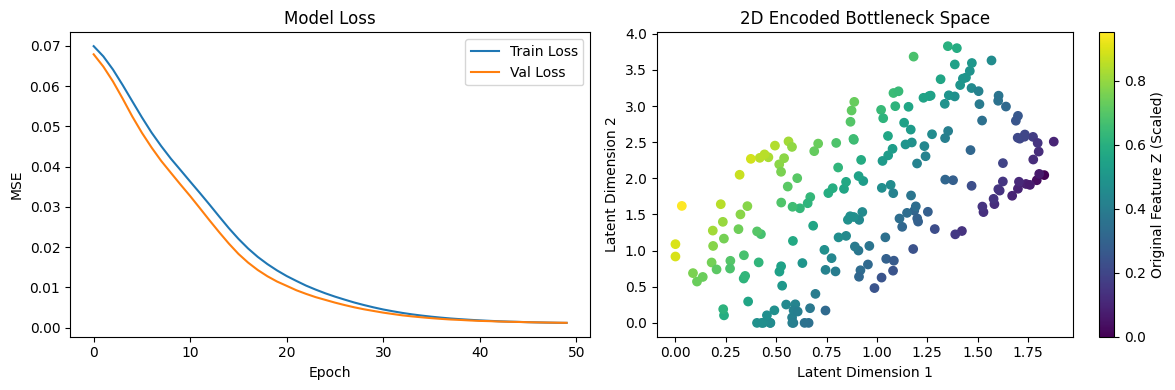

Side-by-side comparison of original and reconstructed 3D values (first 10 samples):


,Original_X,Reconstructed_X,Original_Y,Reconstructed_Y,Original_Z,Reconstructed_Z
0,-1.191,-1.450,4.344,3.962,10.848,10.811
1,3.166,3.275,-3.054,-3.016,-1.407,-1.941
2,-0.373,-0.544,3.275,3.351,9.165,9.334
3,-1.439,-1.567,1.006,1.320,1.022,0.472
4,4.501,3.373,-3.881,-3.279,-1.996,-2.232
5,4.695,3.444,-3.265,-2.975,-1.089,-0.383
6,-0.375,-0.126,-2.991,-2.943,-7.698,-8.994
7,3.661,2.863,-4.818,-3.992,-7.715,-8.221
8,-4.343,-3.753,2.285,2.690,-0.293,-1.414
9,0.188,0.145,3.512,3.532,11.195,11.205


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Generate synthetic data (3D data with a 2D linear relationship + noise)
np.random.seed(42)
n_samples = 1000
x = np.random.uniform(-5, 5, n_samples)
y = np.random.uniform(-5, 5, n_samples)
z = 2 * x + 3 * y + np.random.normal(0, 1, n_samples)  # 2D plane with noise in 3D space

data = np.vstack((x, y, z)).T

# Scale data between 0 and 1 (standard practice for Autoencoders)
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

X_train, X_test = train_test_split(data_scaled, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
input_dim = X_train.shape[1] # 3
encoding_dim = 2             # Target dimension (compressed representation)

# Encoder
encoder_input = layers.Input(shape=(input_dim,))
encoded = layers.Dense(8, activation='relu')(encoder_input)
bottleneck = layers.Dense(encoding_dim, activation='relu')(encoded)
encoder = models.Model(encoder_input, bottleneck, name="Encoder")

# Decoder
decoder_input = layers.Input(shape=(encoding_dim,))
decoded = layers.Dense(8, activation='relu')(decoder_input)
reconstructed = layers.Dense(input_dim, activation='sigmoid')(decoded) # Sigmoid because data is scaled [0,1]
decoder = models.Model(decoder_input, reconstructed, name="Decoder")

# Full Autoencoder
autoencoder_input = layers.Input(shape=(input_dim,))
encoded_repr = encoder(autoencoder_input)
reconstructed_output = decoder(encoded_repr)
autoencoder = models.Model(autoencoder_input, reconstructed_output, name="Autoencoder")

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()
history = autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, X_test),
    verbose=1
)
# 1. Reduce Dimensions
reduced_features = encoder.predict(X_test)

# 2. Reconstruct Data
reconstructed_data = autoencoder.predict(X_test)

# Plot loss history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

# Plot encoded 2D features
plt.subplot(1, 2, 2)
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=X_test[:, 2], cmap='viridis')
plt.colorbar(label='Original Feature Z (Scaled)')
plt.title('2D Encoded Bottleneck Space')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.tight_layout()
plt.show()

# Inverse transform the scaled original and reconstructed test data to original scale
original_test_unscaled = scaler.inverse_transform(X_test)
reconstructed_test_unscaled = scaler.inverse_transform(reconstructed_data)

# Create a comparison DataFrame for the first 10 test samples
comparison_df = pd.DataFrame({
    'Original_X': original_test_unscaled[:10, 0],
    'Reconstructed_X': reconstructed_test_unscaled[:10, 0],
    'Original_Y': original_test_unscaled[:10, 1],
    'Reconstructed_Y': reconstructed_test_unscaled[:10, 1],
    'Original_Z': original_test_unscaled[:10, 2],
    'Reconstructed_Z': reconstructed_test_unscaled[:10, 2]
})

print("Side-by-side comparison of original and reconstructed 3D values (first 10 samples):")
display(comparison_df.round(3))
